In [3]:
import os
import requests
import json
import numpy as np
import tensorflow as tf
from tensorflow import keras
import mlflow
from typing import Dict, Tuple, List
from dataclasses import dataclass
DATA_PATH = "../../02_data/mnist"
NUM_CLIENTS = 3
NUM_ATTACERS = 1
NUM_NORMAL_CLIENTS = NUM_CLIENTS - NUM_ATTACERS

mlflow.set_tracking_uri("http://localhost:5100")
MLFLOW_EXPERIMENT_NAME = "edge-fl-experiment"

I0000 00:00:1790235674.208363   13008 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
def pull_test_data():
    x_test_binary = requests.get("http://localhost:8555/test-data/test_images.npy")
    x_test_binary.raise_for_status()
    y_test_binary = requests.get("http://localhost:8555/test-data/test_labels.npy")
    y_test_binary.raise_for_status()
    with open("../../02_data/mnist/test_images.npy", "wb") as f:
        f.write(x_test_binary.content)
    with open("../../02_data/mnist/test_labels.npy", "wb") as f:
        f.write(y_test_binary.content)
    x_test = np.load("../../02_data/mnist/test_images.npy", allow_pickle=True)
    y_test = np.load("../../02_data/mnist/test_labels.npy", allow_pickle=True)
    return x_test, y_test

x_test, y_test = pull_test_data()

np.savez(
    "../../02_data/agg_test/course_test.npz",
    x_test=x_test,
    y_test=y_test,
)

In [1]:
!docker run --name aggregator_test -d --rm \
    -p 5100:5000 -p 9100:8000 \
    -v "$(realpath ../../02_data/agg_test):/data" \
    ghcr.io/bencefarkas27/aggregator:test-auth

8b6adea2e56d8a8e0730550f6b58a98e650c748751132e72a63810a1174d5d7f


In [4]:
response = requests.get("http://localhost:9100/health")
print(f"Health check response of aggregator: {response.status_code} - {response.text}")

Health check response of aggregator: 200 - 


In [7]:
os.environ["MLFLOW_TRACKING_USERNAME"] = "admin"
with open("../../04_deploy/aggregator/cfg/mlflow_admin.json", "r") as f:
                admin_config = json.load(f)
os.environ["MLFLOW_TRACKING_PASSWORD"] = admin_config["admin_password"]
mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1790173441211, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1790173441211, lifecycle_stage='active', name='edge-fl-experiment', tags={}, trace_location=None, workspace='default'>

In [8]:
def create_dummy_model(input_shape):
    model = keras.Sequential([
        keras.layers.InputLayer(shape=input_shape),
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dense(10, activation='softmax')
    ])
    return model

def mlflow_load_model(model_name):
    response = requests.get(f"http://localhost:8555/{model_name}.weights.h5")
    response.raise_for_status()
    weights_path = f"{model_name}.weights.h5"
    with open(weights_path, "wb") as f:
        f.write(response.content)
    input_shape = os.environ.get("MLFLOW_INPUT_SHAPE", (28, 28))
    model = create_dummy_model(input_shape=input_shape)
    model.load_weights(weights_path)
    model.compile(optimizer='adam',
                    loss='sparse_categorical_crossentropy',
                    metrics=['accuracy'])
    with mlflow.start_run(run_name=f"{model_name}_run") as run:
        # Log the model to MLflow
        mlflow.tensorflow.log_model(model, f"{model_name}_model")
        return run.info.run_id

def get_run_ids():
    experiment = mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT_NAME)
    runs_df = mlflow.search_runs([experiment.experiment_id])
    run_ids = runs_df["run_id"].tolist()
    run_ids.reverse()
    return run_ids


In [9]:
mlflow_load_model("aggregated")
for client_id in range(NUM_CLIENTS):
        mlflow_load_model(f"client_{client_id}")
run_ids = get_run_ids()
for client_id in range(NUM_CLIENTS):
        x_train_binary = requests.get(f"http://localhost:8555/client_data/client_{client_id}_train_images.npy")
        with open(f"../../02_data/mnist/client_data/client_{client_id}_train_images.npy", "wb") as f:
            f.write(x_train_binary.content)

2026/09/23 16:25:05 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:25:07 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run aggregated_run at: http://localhost:5100/#/experiments/1/runs/ab9aa9bc71054cb2bfdfdcee341d04dc
🧪 View experiment at: http://localhost:5100/#/experiments/1


2026/09/23 16:25:24 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:25:26 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run client_0_run at: http://localhost:5100/#/experiments/1/runs/89a4963805e940aeafc4dd5e1ade5694
🧪 View experiment at: http://localhost:5100/#/experiments/1


2026/09/23 16:25:38 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:25:39 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run client_1_run at: http://localhost:5100/#/experiments/1/runs/728d50dab5414306b868a6a4e1d4a489
🧪 View experiment at: http://localhost:5100/#/experiments/1


2026/09/23 16:25:51 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:25:52 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run client_2_run at: http://localhost:5100/#/experiments/1/runs/f9c825514026427da10d52a05e20f55e
🧪 View experiment at: http://localhost:5100/#/experiments/1


In [10]:
def call_do_agg_with_deltarep():
    client_ids = run_ids[1:]
    aggregation_config = {
        "local_model_hosts": [
            "http://localhost:5000"
            for _ in range(NUM_CLIENTS)
        ],
        "local_model_uris": [
            f"runs:/{client_ids[client_id]}/client_{client_id}_model"
            for client_id in range(NUM_CLIENTS)
        ],
        "local_data_size": [
            len(np.load(f"../../02_data/mnist/client_data/client_{client_id}_train_images.npy"))
            for client_id in range(NUM_CLIENTS)
        ],
        "aggregation_algorithm": "deltarep",
        "global_model_host": "http://localhost:5000",
        "global_model_uri": f"runs:/{run_ids[0]}/aggregated_model"            
    }
    response = requests.post("http://localhost:9100/aggregate_models", json=aggregation_config)
    response.raise_for_status()
    return response
    

In [11]:
response = call_do_agg_with_deltarep()
print(response.json())
reputations = response.json()["reputations_scores"]
print(reputations)

{'aggregated_model_host_external': 'http://localhost:5100', 'aggregated_model_host_organizational': 'http://aggregator:5000', 'aggregated_model_uri': 'models:/m-90f34337da924bc6b0da12c426265b38', 'aggregated_model_username': 'model_user', 'aggregated_model_password': 'hiPMMENYuzajkO_vuq9owKnV3ORxRSapm7GgpNw9BAU', 'reputations_scores': {'client_0': 0.24531245549667444, 'client_1': -0.000728587798881695, 'client_2': -0.24458386769779275}}
{'client_0': 0.24531245549667444, 'client_1': -0.000728587798881695, 'client_2': -0.24458386769779275}


In [12]:
client_reputations = {
    "client_0" : [reputations["client_0"]],
    "client_1" : [reputations["client_1"]],
    "client_2" : [reputations["client_2"]],
}
print(client_reputations)

{'client_0': [0.24531245549667444], 'client_1': [-0.000728587798881695], 'client_2': [-0.24458386769779275]}


In [13]:
def pull_and_eval(prev_agg_id, loop_cycle=""):
    # Search the experiment and retrieve the runs
    experiment = mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT_NAME)
    models = mlflow.search_logged_models(
        experiment_ids=[experiment.experiment_id],
        order_by=[{"field_name": "creation_time", "ascending": False}],
        output_format="list"
    )
    new_aggregated = models[0]
    new_aggregated_model = mlflow.tensorflow.load_model(f"models:/{new_aggregated.model_id}")
    new_aggregated_model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    run_name = f"runs:/{prev_agg_id}/deltarep_cycle{loop_cycle}_model" if loop_cycle else f"runs:/{prev_agg_id}/aggregated_model"
    previous_aggregated_model = mlflow.tensorflow.load_model(run_name)
    previous_aggregated_model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    new_aggregated_loss, new_aggregated_accuracy = new_aggregated_model.evaluate(x_test, y_test, verbose=0)
    print(f"New Aggregated Model - Loss: {new_aggregated_loss}, Accuracy: {new_aggregated_accuracy}")

    previous_aggregated_loss, previous_aggregated_accuracy = previous_aggregated_model.evaluate(x_test, y_test, verbose=0)
    print(f"Previous Aggregated Model - Loss: {previous_aggregated_loss}, Accuracy: {previous_aggregated_accuracy}")

    return new_aggregated_model, previous_aggregated_model

In [14]:
new_aggregated_model, previous_aggregated_model = pull_and_eval(get_run_ids()[0])

/home/barkas/miniconda3/envs/edge-test/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:843: UserWarning: Skipping variable loading for optimizer 'adam', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


New Aggregated Model - Loss: 11.982089042663574, Accuracy: 0.22759999334812164
Previous Aggregated Model - Loss: 37.268497467041016, Accuracy: 0.2921000123023987


In [15]:
new_aggregated_model.save_weights("dummy_models/deltarep_cycle1.weights.h5")
with mlflow.start_run(run_name=f"deltarep_cycle1") as run:
        # Log the model to MLflow
        mlflow.tensorflow.log_model(new_aggregated_model, f"deltarep_cycle1_model")
print(run.info.run_id)

2026/09/23 16:27:28 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:27:30 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run deltarep_cycle1 at: http://localhost:5100/#/experiments/1/runs/df94d96d737d4ee982ff119dfa0aff25
🧪 View experiment at: http://localhost:5100/#/experiments/1
df94d96d737d4ee982ff119dfa0aff25


In [16]:
# -----------------------------
# Attacks on model updates (delta)
# -----------------------------
WeightList = List[np.ndarray]
def sign_flip(delta: WeightList) -> WeightList:
    return [(-weights).copy() for weights in delta]

def scaled_sign_flip(delta: WeightList, scale_factor: float) -> WeightList:
    return [(-weights * scale_factor).copy() for weights in delta]

def add_noise(delta: WeightList, sigma: float) -> WeightList:
    return [
        (weights + sigma * np.random.randn(*weights.shape)).astype(weights.dtype)
        for weights in delta
    ]
@dataclass
class AttackSpec:
    attack_type: str
    scale_factor: float = 5.0 # gamma
    noise_level: float = 0.1  # sigma

class AttackManager:
    def __init__(self, client_specs: Dict[int, AttackSpec]):
        self.client_specs = client_specs
    def apply(self, client_id: int, delta: WeightList, round: int) -> Tuple[WeightList, str]:
        spec = self.client_specs.get(client_id, AttackSpec("none"))
        type = spec.attack_type.lower()
        if type == "none":
            return delta, "none"
        attacked_delta = [w.copy() for w in delta]
        if type == "sign_flip":
            attacked_delta = sign_flip(attacked_delta)
        elif type == "scaled":
            attacked_delta = scaled_sign_flip(attacked_delta, spec.scale_factor)
        elif type == "random_noise":
            attacked_delta = add_noise(attacked_delta, spec.noise_level)

        return attacked_delta, type

In [17]:
def retrain_clients_on_new_aggregate(loop_cycle, run_id, attack_manager):
    for client_id in range(NUM_CLIENTS):
        # Load the new aggregated model weights into the client model
        client_model = mlflow.tensorflow.load_model(f"runs:/{run_id}/deltarep_cycle{loop_cycle}_model")
        weights_before_training = [
            weights.copy()
            for weights in client_model.get_weights()
        ]
        x_train_binary = requests.get(f"http://localhost:8555/client_data/client_{client_id}_train_images.npy")
        with open(f"../../02_data/mnist/client_data/client_{client_id}_train_images.npy", "wb") as f:
            f.write(x_train_binary.content)
        y_train_binary = requests.get(f"http://localhost:8555/client_data/client_{client_id}_train_labels.npy")
        with open(f"../../02_data/mnist/client_data/client_{client_id}_train_labels.npy", "wb") as f:
            f.write(y_train_binary.content)
        x_train = np.load(f"../../02_data/mnist/client_data/client_{client_id}_train_images.npy", allow_pickle=True)
        y_train = np.load(f"../../02_data/mnist/client_data/client_{client_id}_train_labels.npy", allow_pickle=True)
        client_model.compile(optimizer='adam',
                             loss='sparse_categorical_crossentropy',
                             metrics=['accuracy'])
        client_model.fit(x_train, y_train, epochs=3)
        delta = [after - before
                 for after, before in zip(client_model.get_weights(), weights_before_training)
        ]
        delta, attack_type = attack_manager.apply(client_id, delta, loop_cycle)
        final_weights = [before + d for before, d in zip(weights_before_training, delta)]
        client_model.set_weights(final_weights)
        with mlflow.start_run(run_name=f"client_{client_id}_run_{loop_cycle}") as run:
                # Log the model to MLflow
                mlflow.tensorflow.log_model(client_model, f"client_{client_id}_model_{loop_cycle}")

        client_model.save_weights(f"dummy_models/cycle{loop_cycle}/client_{client_id}.weights.h5")  


def rerun_deltarep_aggregation(loop_cycle):
    run_ids = get_run_ids()[-4:]
    print(run_ids)
    clients_ids = run_ids[1:]
    aggregation_config = {
            "local_model_hosts": [
                "http://localhost:5000"
                for _ in range(NUM_CLIENTS)
            ],
            "local_model_uris": [
                f"runs:/{clients_ids[client_id]}/client_{client_id}_model_{loop_cycle}"
                for client_id in range(NUM_CLIENTS)
            ],
            "local_data_size": [
                len(np.load(f"../../02_data/mnist/client_data/client_{client_id}_train_images.npy"))
                for client_id in range(NUM_CLIENTS)
            ],
            "aggregation_algorithm": "deltarep",
            "global_model_host": "http://localhost:5000",
            "global_model_uri": f"runs:/{run_ids[0]}/deltarep_cycle{loop_cycle}_model"            
        }
    response = requests.post("http://localhost:9100/aggregate_models", json=aggregation_config)
    response.raise_for_status()
    return response

In [18]:
attack_manager = AttackManager({
        0: AttackSpec("none"),
        1: AttackSpec("none"),
        2: AttackSpec("sign_flip")
    })

In [20]:
prev_agg_id = get_run_ids()[-1]
retrain_clients_on_new_aggregate(loop_cycle=1, run_id=prev_agg_id, attack_manager=attack_manager)
response = rerun_deltarep_aggregation(loop_cycle=1)
new_aggregated_model, previous_aggregated_model = pull_and_eval(prev_agg_id, loop_cycle=1)

new_aggregated_model.save_weights("dummy_models/deltarep_cycle2.weights.h5")
with mlflow.start_run(run_name=f"deltarep_cycle2") as run:
        # Log the model to MLflow
        mlflow.tensorflow.log_model(new_aggregated_model, f"deltarep_cycle2_model")
print(run.info.run_id)

Epoch 1/3


W0000 00:00:1790173929.132034   10060 cpu_allocator_impl.cc:82] Allocation of 19264448 exceeds 10% of free system memory.


768/768 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9790 - loss: 0.1620
Epoch 2/3
768/768 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9864 - loss: 0.0644
Epoch 3/3
768/768 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9899 - loss: 0.0421


2026/09/23 16:32:20 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:32:21 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run client_0_run_1 at: http://localhost:5100/#/experiments/1/runs/4efd398e08ab444190bffa9b7bbc464e
🧪 View experiment at: http://localhost:5100/#/experiments/1
Epoch 1/3


...

🏃 View run client_1_run_1 at: http://localhost:5100/#/experiments/1/runs/1e390aa8e82e4ad1b8936e821d920083
🧪 View experiment at: http://localhost:5100/#/experiments/1
Epoch 1/3
564/564 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9676 - loss: 0.2548
Epoch 2/3
564/564 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9904 - loss: 0.0379
Epoch 3/3
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9930 - loss: 0.0289


2026/09/23 16:33:12 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:33:13 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run client_2_run_1 at: http://localhost:5100/#/experiments/1/runs/dfb8b1d876ac4498928cd0a818917be9
🧪 View experiment at: http://localhost:5100/#/experiments/1
['df94d96d737d4ee982ff119dfa0aff25', '4efd398e08ab444190bffa9b7bbc464e', '1e390aa8e82e4ad1b8936e821d920083', 'dfb8b1d876ac4498928cd0a818917be9']
New Aggregated Model - Loss: 11.38952350616455, Accuracy: 0.40939998626708984
Previous Aggregated Model - Loss: 11.982089042663574, Accuracy: 0.22759999334812164


2026/09/23 16:34:15 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:34:16 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run deltarep_cycle2 at: http://localhost:5100/#/experiments/1/runs/c7745c9a9e2041a7b109a47c9a4335fa
🧪 View experiment at: http://localhost:5100/#/experiments/1
c7745c9a9e2041a7b109a47c9a4335fa


In [21]:
reputations = response.json()["reputations_scores"]
print(reputations)
client_reputations["client_0"].append(reputations["client_0"])
client_reputations["client_1"].append(reputations["client_1"])
client_reputations["client_2"].append(reputations["client_2"])
print(client_reputations)

{'client_0': 0.34305412434785637, 'client_1': 0.13538649952489093, 'client_2': -0.47844062387274733}
{'client_0': [0.24531245549667444, 0.34305412434785637], 'client_1': [-0.000728587798881695, 0.13538649952489093], 'client_2': [-0.24458386769779275, -0.47844062387274733]}


In [22]:
prev_agg_id = get_run_ids()[-1]
retrain_clients_on_new_aggregate(loop_cycle=2, run_id=prev_agg_id, attack_manager=attack_manager)
response = rerun_deltarep_aggregation(loop_cycle=2)
new_aggregated_model, previous_aggregated_model = pull_and_eval(prev_agg_id, loop_cycle=2)
new_aggregated_model.save_weights("dummy_models/deltarep_cycle3.weights.h5")
with mlflow.start_run(run_name=f"deltarep_cycle3") as run:
        # Log the model to MLflow
        mlflow.tensorflow.log_model(new_aggregated_model, f"deltarep_cycle3_model")
print(run.info.run_id)

/home/barkas/miniconda3/envs/edge-test/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:843: UserWarning: Skipping variable loading for optimizer 'adam_10', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Epoch 1/3
768/768 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9853 - loss: 0.1133
Epoch 2/3
768/768 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9910 - loss: 0.0463
Epoch 3/3
768/768 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9912 - loss: 0.0453


2026/09/23 16:35:10 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:35:11 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run client_0_run_2 at: http://localhost:5100/#/experiments/1/runs/88edb3091d414386868b8aa93eace193
🧪 View experiment at: http://localhost:5100/#/experiments/1
Epoch 1/3


W0000 00:00:1790174126.764512   10060 cpu_allocator_impl.cc:82] Allocation of 13636896 exceeds 10% of free system memory.


...

🏃 View run client_1_run_2 at: http://localhost:5100/#/experiments/1/runs/c912db6375b34fa9a6e22b775a4aec3b
🧪 View experiment at: http://localhost:5100/#/experiments/1
Epoch 1/3
564/564 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8934 - loss: 0.5486
Epoch 2/3
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9864 - loss: 0.0478
Epoch 3/3
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9896 - loss: 0.0353


2026/09/23 16:35:59 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:36:01 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run client_2_run_2 at: http://localhost:5100/#/experiments/1/runs/cb67c1fcef3945089fa467402ab6d874
🧪 View experiment at: http://localhost:5100/#/experiments/1
['c7745c9a9e2041a7b109a47c9a4335fa', '88edb3091d414386868b8aa93eace193', 'c912db6375b34fa9a6e22b775a4aec3b', 'cb67c1fcef3945089fa467402ab6d874']
New Aggregated Model - Loss: 12.835521697998047, Accuracy: 0.4447000026702881
Previous Aggregated Model - Loss: 11.38952350616455, Accuracy: 0.40939998626708984


2026/09/23 16:37:01 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:37:02 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run deltarep_cycle3 at: http://localhost:5100/#/experiments/1/runs/78927026d85241efabc4bc5c509c9640
🧪 View experiment at: http://localhost:5100/#/experiments/1
78927026d85241efabc4bc5c509c9640


In [23]:
reputations = response.json()["reputations_scores"]
print(reputations)
client_reputations["client_0"].append(reputations["client_0"])
client_reputations["client_1"].append(reputations["client_1"])
client_reputations["client_2"].append(reputations["client_2"])
print(client_reputations)

{'client_0': 0.41192258737738785, 'client_1': 0.25363633041382005, 'client_2': -0.665558917791208}
{'client_0': [0.24531245549667444, 0.34305412434785637, 0.41192258737738785], 'client_1': [-0.000728587798881695, 0.13538649952489093, 0.25363633041382005], 'client_2': [-0.24458386769779275, -0.47844062387274733, -0.665558917791208]}


In [24]:
for loop_cycle in range(3, 4):
    prev_agg_id = get_run_ids()[-1]
    retrain_clients_on_new_aggregate(loop_cycle=loop_cycle, run_id=prev_agg_id, attack_manager=attack_manager)
    response =rerun_deltarep_aggregation(loop_cycle=loop_cycle)
    new_aggregated_model, previous_aggregated_model = pull_and_eval(prev_agg_id, loop_cycle=loop_cycle)
    new_aggregated_model.save_weights(f"dummy_models/deltarep_cycle{loop_cycle+1}.weights.h5")
    with mlflow.start_run(run_name=f"deltarep_cycle{loop_cycle+1}") as run:
            # Log the model to MLflow
            mlflow.tensorflow.log_model(new_aggregated_model, f"deltarep_cycle{loop_cycle+1}_model")
    print(run.info.run_id)
    reputations = response.json()["reputations_scores"]
    client_reputations["client_0"].append(reputations["client_0"])
    client_reputations["client_1"].append(reputations["client_1"])
    client_reputations["client_2"].append(reputations["client_2"])

/home/barkas/miniconda3/envs/edge-test/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:843: UserWarning: Skipping variable loading for optimizer 'adam_15', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Epoch 1/3


W0000 00:00:1790174315.749815   10060 cpu_allocator_impl.cc:82] Allocation of 19264448 exceeds 10% of free system memory.


768/768 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9902 - loss: 0.0709
Epoch 2/3
768/768 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9920 - loss: 0.0517
Epoch 3/3
768/768 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9924 - loss: 0.0449


2026/09/23 16:38:47 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:38:48 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


...

🏃 View run client_1_run_3 at: http://localhost:5100/#/experiments/1/runs/a97b4cd12ef7469db4de3cee8e0aa9d9
🧪 View experiment at: http://localhost:5100/#/experiments/1
Epoch 1/3
564/564 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7598 - loss: 0.8450
Epoch 2/3
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9839 - loss: 0.0553
Epoch 3/3
564/564 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9864 - loss: 0.0453


2026/09/23 16:39:37 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:39:39 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run client_2_run_3 at: http://localhost:5100/#/experiments/1/runs/376e170ac5244ffc80a02cd89bd7e5a4
🧪 View experiment at: http://localhost:5100/#/experiments/1
['78927026d85241efabc4bc5c509c9640', '6683978e0e5f47d4bf72face9e8b8b6a', 'a97b4cd12ef7469db4de3cee8e0aa9d9', '376e170ac5244ffc80a02cd89bd7e5a4']
New Aggregated Model - Loss: 17.275360107421875, Accuracy: 0.4410000145435333
Previous Aggregated Model - Loss: 12.835521697998047, Accuracy: 0.4447000026702881


2026/09/23 16:40:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:40:38 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run deltarep_cycle4 at: http://localhost:5100/#/experiments/1/runs/463a0fa4a49849968d7fd44214d76057
🧪 View experiment at: http://localhost:5100/#/experiments/1
463a0fa4a49849968d7fd44214d76057


In [25]:
print(client_reputations)

{'client_0': [0.24531245549667444, 0.34305412434785637, 0.41192258737738785, 0.43362922717592667], 'client_1': [-0.000728587798881695, 0.13538649952489093, 0.25363633041382005, 0.3786216320533317], 'client_2': [-0.24458386769779275, -0.47844062387274733, -0.665558917791208, -0.8122508592292585]}


In [26]:
attack_manager = AttackManager({
        0: AttackSpec("none"),
        1: AttackSpec("random_noise"),
        2: AttackSpec("none")
    })

In [27]:
for loop_cycle in range(4, 7):
    prev_agg_id = get_run_ids()[-1]
    retrain_clients_on_new_aggregate(loop_cycle=loop_cycle, run_id=prev_agg_id, attack_manager=attack_manager)
    response =rerun_deltarep_aggregation(loop_cycle=loop_cycle)
    new_aggregated_model, previous_aggregated_model = pull_and_eval(prev_agg_id, loop_cycle=loop_cycle)
    new_aggregated_model.save_weights(f"dummy_models/deltarep_cycle{loop_cycle+1}.weights.h5")
    with mlflow.start_run(run_name=f"deltarep_cycle{loop_cycle+1}") as run:
            # Log the model to MLflow
            mlflow.tensorflow.log_model(new_aggregated_model, f"deltarep_cycle{loop_cycle+1}_model")
    print(run.info.run_id)
    reputations = response.json()["reputations_scores"]
    client_reputations["client_0"].append(reputations["client_0"])
    client_reputations["client_1"].append(reputations["client_1"])
    client_reputations["client_2"].append(reputations["client_2"])

/home/barkas/miniconda3/envs/edge-test/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:843: UserWarning: Skipping variable loading for optimizer 'adam_20', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Epoch 1/3
768/768 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9924 - loss: 0.0604
Epoch 2/3
768/768 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9935 - loss: 0.0363
Epoch 3/3
768/768 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9934 - loss: 0.0440


2026/09/23 16:42:51 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:42:52 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run client_0_run_4 at: http://localhost:5100/#/experiments/1/runs/d08254df6da14c7a9f55b11eab7df198
🧪 View experiment at: http://localhost:5100/#/experiments/1
Epoch 1/3
544/544 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9700 - loss: 0.2021
Epoch 2/3
544/544 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9871 - loss: 0.0450
Epoch 3/3
544/544 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9871 - loss: 0.0495


2026/09/23 16:43:14 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:43:15 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


...

🏃 View run client_2_run_5 at: http://localhost:5100/#/experiments/1/runs/4f4f5ce425c3492bae07c21d351f81b9
🧪 View experiment at: http://localhost:5100/#/experiments/1
['c3cfcd31414741b280d916b0bd57d3fb', 'fcc17fc8948f4fd6aa89a13d568e4bca', '03ddf961ca294df696e0438151524674', '4f4f5ce425c3492bae07c21d351f81b9']
New Aggregated Model - Loss: 11.35062313079834, Accuracy: 0.40139999985694885
Previous Aggregated Model - Loss: 14.95499038696289, Accuracy: 0.38100001215934753


2026/09/23 16:47:08 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/23 16:47:09 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


🏃 View run deltarep_cycle6 at: http://localhost:5100/#/experiments/1/runs/abb44a211f99415a8376d9a9027ca087
🧪 View experiment at: http://localhost:5100/#/experiments/1
abb44a211f99415a8376d9a9027ca087


/home/barkas/miniconda3/envs/edge-test/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:843: UserWarning: Skipping variable loading for optimizer 'adam_30', because it has 10 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


ConnectionError: ('Connection aborted.', ConnectionResetError(104, 'Connection reset by peer'))

In [ ]:
print(client_reputations)

{'client_0': [0.24531245549667444, 0.3394409076929956, 0.37182629584719357, 0.41600924477747253, 0.41769384020281036, 0.42633388758242596, 0.36617955002878233], 'client_1': [-0.000728587798881695, 0.13906148702460291, 0.2901515027801478, 0.3952425607342215, 0.040093558865465506, -0.24559024908867738, -0.4530100251560343], 'client_2': [-0.24458386769779275, -0.4785023947175986, -0.6619777986273414, -0.8112518055116941, -0.4577873990682759, -0.18074363849374855, 0.08683047512725192]}


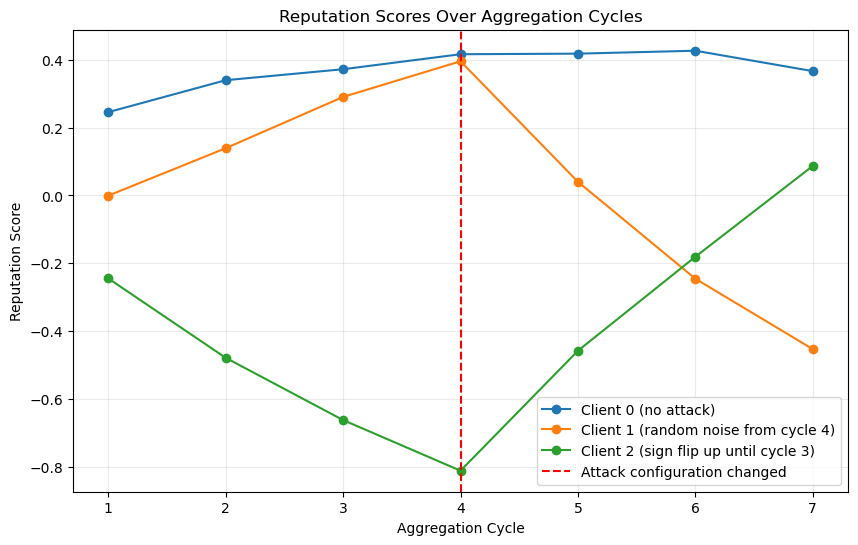

In [ ]:
from matplotlib import pyplot as plt
fig, ax = plt.subplots(figsize=(10, 6))
attack_labels = {
    0: "Client 0 (no attack)",
    1: "Client 1 (random noise from cycle 4)",
    2: "Client 2 (sign flip up until cycle 3)",
}
for client_id in range(NUM_CLIENTS):
    scores = client_reputations[f"client_{client_id}"]
    ax.plot(
        range(1, len(scores) + 1),
        scores,
        marker='o',
        label=attack_labels[client_id]
    )
ax.axvline(4, color='red', linestyle='--', label='Attack configuration changed')
ax.set_title("Reputation Scores Over Aggregation Cycles")
ax.set_xlabel("Aggregation Cycle")
ax.set_ylabel("Reputation Score")
ax.legend()
ax.grid(alpha=0.25)

plt.show()

In [ ]:
min_reputation_cycle_client_1 = np.argmin(client_reputations["client_1"])
min_reputation_cycle_client_2 = np.argmin(client_reputations["client_2"])
print(f"Client 1 minimum reputation cycle: {min_reputation_cycle_client_1}")
print(f"Client 2 minimum reputation cycle: {min_reputation_cycle_client_2}")

In [5]:
!docker stop aggregator_test

aggregator_test
